In [560]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

In [561]:
file = "/content/drive/MyDrive/Dataset/quickkart_customers.csv"
df_order = pd.read_csv(file)

In [562]:
df_order.describe()

,Age,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
count,1419.000000,1346.000000,1500.000000,1376.000000,1500.000000
mean,34.248062,43418.424963,8.986667,817.260901,5723.821333
std,10.554268,62967.813712,15.567661,1805.319096,6497.750986
min,-3.000000,5500.000000,1.000000,81.000000,157.000000
25%,27.000000,24100.000000,4.000000,401.000000,1937.750000
50%,34.000000,33600.000000,7.000000,579.500000,3820.500000
75%,41.000000,47300.000000,11.000000,868.250000,7280.250000
max,150.000000,900000.000000,310.000000,35000.000000,85073.000000


In [563]:
df_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1500 non-null   object 
 1   Age               1419 non-null   float64
 2   Gender            1449 non-null   object 
 3   City              1434 non-null   object 
 4   Membership        1500 non-null   object 
 5   Payment_Mode      1405 non-null   object 
 6   Monthly_Income    1346 non-null   float64
 7   Orders_Last_Year  1500 non-null   float64
 8   Avg_Order_Value   1376 non-null   float64
 9   Total_Spent       1500 non-null   float64
dtypes: float64(5), object(5)
memory usage: 117.3+ KB


In [564]:
df_order.dtypes

,0
Customer_ID,object
Age,float64
Gender,object
City,object
Membership,object
Payment_Mode,object
Monthly_Income,float64
Orders_Last_Year,float64
Avg_Order_Value,float64
Total_Spent,float64


In [565]:
df_order.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0


In [566]:
df_order.isna().sum()

,0
Customer_ID,0
Age,81
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [567]:
num_cols = df_order.select_dtypes(include=['number']).columns
cat_cols = df_order .select_dtypes(include=['object']).columns

num_cols

Index(['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value',
       'Total_Spent'],
      dtype='object')

In [568]:
type(num_cols)

pandas.core.indexes.base.Index

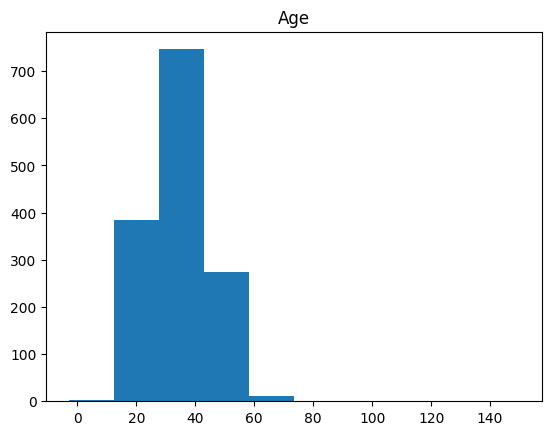

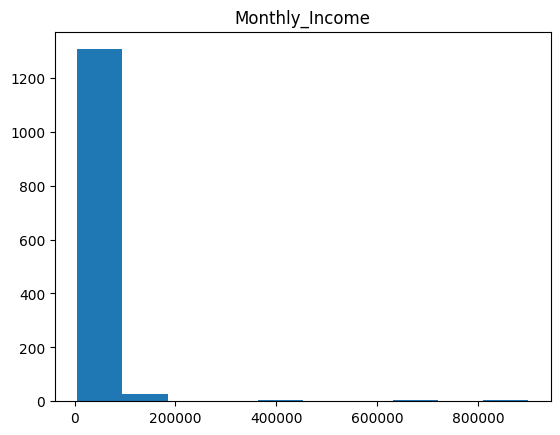

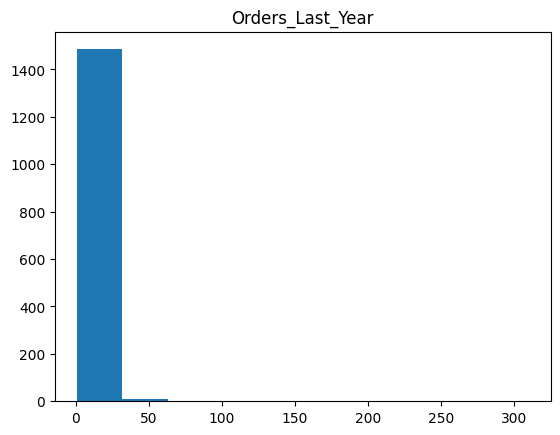

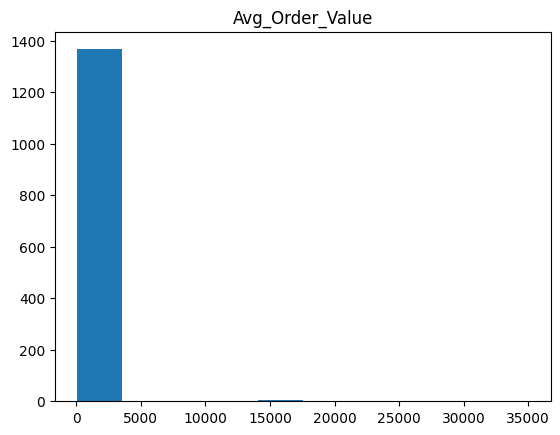

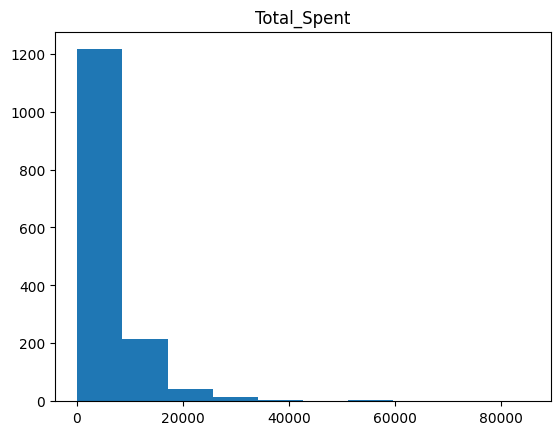

In [569]:
for col in num_cols:
    plt.hist(df_order[col])
    plt.title(col)
    plt.show()

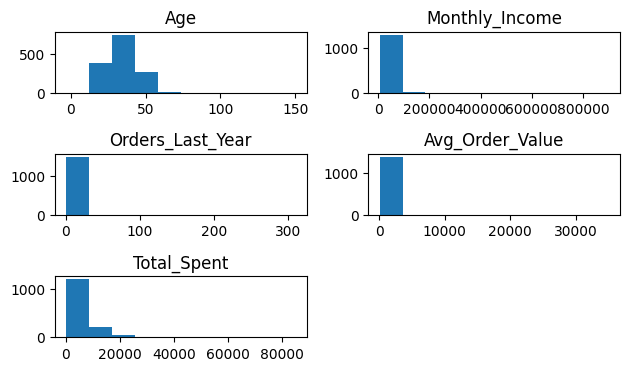

In [570]:
#creating a subplot to see all charts at once
for i, col in enumerate(num_cols, 1):
  plt.subplot(4, 2, i)
  plt.hist(df_order[col])
  plt.title(col)
  plt.tight_layout()
plt.show()

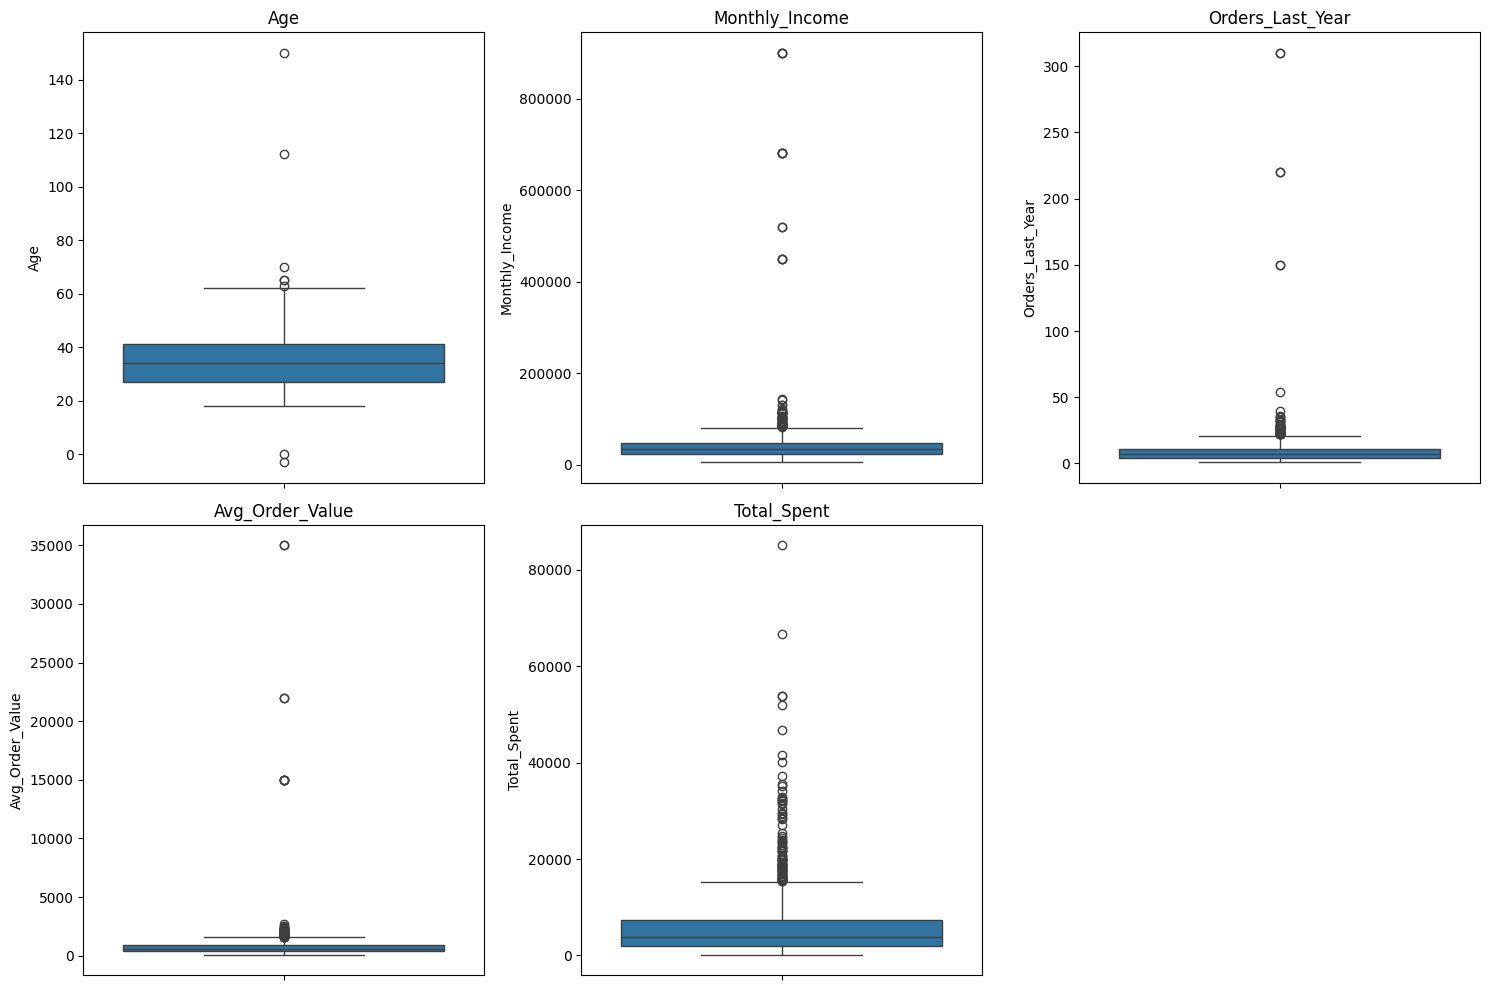

In [571]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
  plt.subplot(2, 3, i)
  sns.boxplot(y=df_order[col])
  plt.title(col)
  plt.tight_layout()
plt.show()

In [572]:
df_order.isna().sum()

,0
Customer_ID,0
Age,81
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [573]:
num_cols


Index(['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value',
       'Total_Spent'],
      dtype='object')

In [574]:
df_order = pd.read_csv(file)

# Fill missing values on freshly loaded data
df_order['Age'] = df_order['Age'].fillna(df_order['Age'].median())
df_order['Monthly_Income'] = df_order['Monthly_Income'].fillna(df_order['Monthly_Income'].median())
df_order['Orders_Last_Year'] = df_order['Orders_Last_Year'].fillna(df_order['Orders_Last_Year'].median())
df_order['Avg_Order_Value'] = df_order['Avg_Order_Value'].fillna(df_order['Avg_Order_Value'].median())
df_order['Total_Spent'] = df_order['Total_Spent'].fillna(df_order['Total_Spent'].median())

# Verify that the missing values for numeric columns are resolved
display(df_order.isna().sum())

,0
Customer_ID,0
Age,0
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0


In [575]:
df_order.isna().sum()

,0
Customer_ID,0
Age,0
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0


In [576]:
df_order['Customer_ID'] = df_order['Customer_ID'].fillna(df_order['Customer_ID'].mode()[0])
df_order['Gender'] = df_order['Gender'].fillna(df_order['Gender'].mode()[0])
df_order['City'] = df_order['City'].fillna(df_order['City'].mode()[0])
df_order['Payment_Mode'] = df_order['Payment_Mode'].fillna(df_order['Payment_Mode'].mode()[0])

In [577]:
df_order.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0


In [578]:
df_order.isna().sum()

,0
Customer_ID,0
Age,0
Gender,0
City,0
Membership,0
Payment_Mode,0
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0


In [579]:
Q1 = df_order[num_cols].quantile(0.25)
Q3 = df_order[num_cols].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)
lower_limit = Q1 - (1.5 * IQR)

outliers = ((df_order[num_cols] > upper_limit) | (df_order[num_cols] < lower_limit))


df_order = df_order[~outliers.any(axis=1)]

print(f"after outlier handling : shape {df_order.shape}")

after outlier handling : shape (1251, 10)


In [580]:
df_order.shape

(1251, 10)

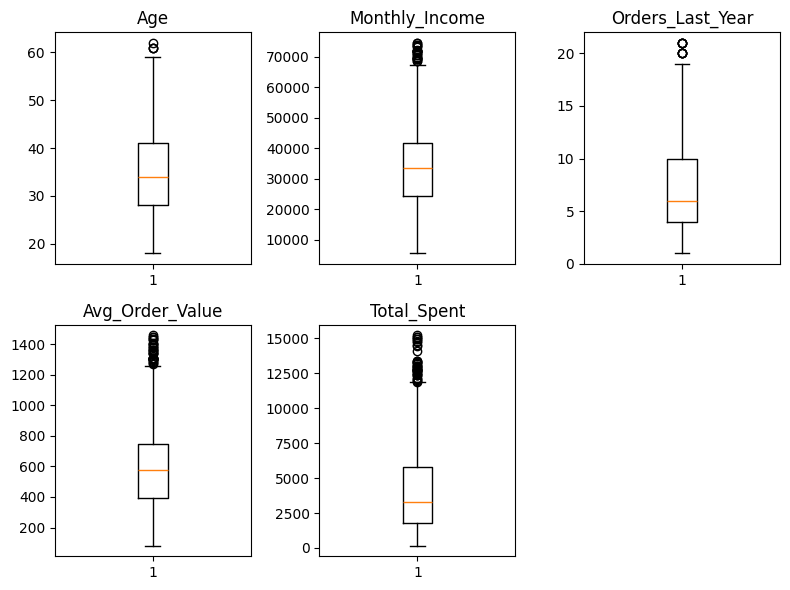

In [581]:
plt.figure(figsize=(8, 6))
for i, col in enumerate(num_cols_to_scale, 1):
    plt.subplot(2, 3, i)
    plt.boxplot(df_order[col])
    plt.title(col)
    plt.tight_layout()
plt.show()

In [582]:
df_order.duplicated().sum()

np.int64(29)

In [583]:
df_order.drop_duplicates(inplace=True)

In [584]:
df_order.duplicated().sum()


np.int64(0)

In [585]:
df_order.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
5,C0800,24.0,Male,Kozhikode,Gold,Credit Card,32100.0,14.0,480.0,6344.0
6,C1440,29.0,Male,Kollam,Silver,Debit Card,38000.0,16.0,260.0,3890.0
8,C1200,18.0,Female,Kochi,Silver,Cash on Delivery,66400.0,8.0,440.0,3643.0


In [586]:
df_order["Gender"].unique()

array(['Female', 'Male', 'Other', 'F', 'M'], dtype=object)

In [587]:
df_order['Gender'] = df_order['Gender'].replace({'F': 'Female', 'M': 'Male'})

In [588]:
df_order["Gender"].unique()

array(['Female', 'Male', 'Other'], dtype=object)

In [589]:
encoder = OneHotEncoder()
encoded_data = encoder.fit_transform(df_order[["Gender"]])

encoded_df_order = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder.get_feature_names_out(["Gender"]),
    index = df_order.index
    )

df_order = pd.concat([df_order, encoded_df_order], axis=1).drop(columns=["Gender"])

In [590]:
df_order.head(20)

,Customer_ID,Age,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other
0,C0258,29.0,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0,1.0,0.0,0.0
2,C0993,18.0,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0,0.0,1.0,0.0
5,C0800,24.0,Kozhikode,Gold,Credit Card,32100.0,14.0,480.0,6344.0,0.0,1.0,0.0
6,C1440,29.0,Kollam,Silver,Debit Card,38000.0,16.0,260.0,3890.0,0.0,1.0,0.0
8,C1200,18.0,Kochi,Silver,Cash on Delivery,66400.0,8.0,440.0,3643.0,1.0,0.0,0.0
9,C0516,43.0,kochi,Basic,Debit Card,33300.0,8.0,482.0,3733.0,0.0,1.0,0.0
10,C0517,18.0,Palakkad,Silver,Debit Card,37200.0,2.0,1028.0,2164.0,0.0,1.0,0.0
11,C0749,34.0,Kozhikode,Basic,Credit Card,21000.0,6.0,775.0,4459.0,1.0,0.0,0.0
12,C1261,18.0,Thrissur,Basic,Cash on Delivery,17200.0,7.0,1122.0,7830.0,1.0,0.0,0.0
13,C0938,57.0,Palakkad,Basic,Cash on Delivery,69500.0,6.0,797.0,4512.0,0.0,1.0,0.0


In [591]:
df_order["City"].unique()

array(['Kozhikode', 'Thrissur', 'Kollam', 'Kochi', 'kochi', 'Palakkad',
       'Kannur', 'Alappuzha', 'Trivandrum', 'Kochi ', 'Trivandrum ',
       'TRIVANDRUM', 'kozhikode', 'kollam', 'KOCHI', 'KOLLAM'],
      dtype=object)

In [592]:
df_order['City'] = df_order['City'].str.strip().str.title()

print("Unique Cities:", df_order['City'].unique())

Unique Cities: ['Kozhikode' 'Thrissur' 'Kollam' 'Kochi' 'Palakkad' 'Kannur' 'Alappuzha'
 'Trivandrum']


In [593]:
label_encoder = LabelEncoder()
df_order['City'] = label_encoder.fit_transform(df_order['City'])

#after encoding
df_order['City'].unique()

array([4, 6, 3, 2, 5, 1, 0, 7])

In [594]:
df_order.head()

,Customer_ID,Age,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other
0,C0258,29.0,4,Basic,Debit Card,55900.0,6.0,523.0,3143.0,1.0,0.0,0.0
2,C0993,18.0,6,Basic,UPI,32600.0,2.0,491.0,1007.0,0.0,1.0,0.0
5,C0800,24.0,4,Gold,Credit Card,32100.0,14.0,480.0,6344.0,0.0,1.0,0.0
6,C1440,29.0,3,Silver,Debit Card,38000.0,16.0,260.0,3890.0,0.0,1.0,0.0
8,C1200,18.0,2,Silver,Cash on Delivery,66400.0,8.0,440.0,3643.0,1.0,0.0,0.0


In [595]:
df_order["City"].unique()

array([4, 6, 3, 2, 5, 1, 0, 7])

In [596]:
df_order["Membership"].unique()

array(['Basic', 'Gold', 'Silver', 'SILVER', 'Platinum', 'PLATINUM',
       'silver', 'GOLD', 'basic'], dtype=object)

In [597]:
encoder_members = OrdinalEncoder(
    categories=[['Basic', 'Silver', 'Gold', 'SILVER', 'Platinum', 'PLATINUM',
       'silver', 'GOLD', 'basic']]
)
df_order["Membership"] = encoder_members.fit_transform(df_order[["Membership"]])

In [598]:
df_order.head()

,Customer_ID,Age,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other
0,C0258,29.0,4,0.0,Debit Card,55900.0,6.0,523.0,3143.0,1.0,0.0,0.0
2,C0993,18.0,6,0.0,UPI,32600.0,2.0,491.0,1007.0,0.0,1.0,0.0
5,C0800,24.0,4,2.0,Credit Card,32100.0,14.0,480.0,6344.0,0.0,1.0,0.0
6,C1440,29.0,3,1.0,Debit Card,38000.0,16.0,260.0,3890.0,0.0,1.0,0.0
8,C1200,18.0,2,1.0,Cash on Delivery,66400.0,8.0,440.0,3643.0,1.0,0.0,0.0


In [599]:
df_order["Payment_Mode"].unique()

array(['Debit Card', 'UPI', 'Credit Card', 'Cash on Delivery',
       'Net Banking'], dtype=object)

In [600]:
encoder = OneHotEncoder()
encoded_data = encoder.fit_transform(df_order[["Payment_Mode"]])

encoded_df_order = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder.get_feature_names_out(["Payment_Mode"]),
    index = df_order.index
    )

df_order = pd.concat([df_order, encoded_df_order], axis=1).drop(columns=["Payment_Mode"])

In [601]:
df_order.head()

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI
0,C0258,29.0,4,0.0,55900.0,6.0,523.0,3143.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,C0993,18.0,6,0.0,32600.0,2.0,491.0,1007.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,C0800,24.0,4,2.0,32100.0,14.0,480.0,6344.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
6,C1440,29.0,3,1.0,38000.0,16.0,260.0,3890.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
8,C1200,18.0,2,1.0,66400.0,8.0,440.0,3643.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [602]:
from sklearn.preprocessing import StandardScaler

num_cols_to_scale = ['Age', 'Avg_Order_Value', 'Total_Spent', 'Orders_Last_Year', 'Monthly_Income']

scaler = StandardScaler()


df_order[num_cols_to_scale] = scaler.fit_transform(df_order[num_cols_to_scale])

display(df_order.head(10))

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI
0,C0258,-0.552481,4,0.0,1.588962,-0.245177,-0.286515,-0.327217,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,C0993,-1.722922,6,0.0,-0.127125,-1.164217,-0.405428,-1.000559,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,C0800,-1.084500,4,2.0,-0.163951,1.592902,-0.446304,0.681850,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
6,C1440,-0.552481,3,1.0,0.270595,2.052421,-1.263831,-0.091736,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
8,C1200,-1.722922,2,1.0,2.362306,0.214342,-0.594945,-0.169599,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,C0516,0.937171,2,0.0,-0.075568,0.214342,-0.438872,-0.141228,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
10,C0517,-1.722922,5,1.0,0.211674,-1.164217,1.590082,-0.635832,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
11,C0749,-0.020462,4,0.0,-0.981486,-0.245177,0.649926,0.087632,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
12,C1261,-1.722922,6,0.0,-1.261363,-0.015418,1.939389,1.150290,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
13,C0938,2.426824,5,0.0,2.590627,-0.245177,0.731678,0.104340,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [603]:

num_cols_to_scale = ['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent']
min_max_scaler = MinMaxScaler()
df_order[num_cols_to_scale] = min_max_scaler.fit_transform(df_order[num_cols_to_scale])


display(df_order.head(10))

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI
0,C0258,0.250000,4,0.0,0.730435,0.25,0.321221,0.198379,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,C0993,0.000000,6,0.0,0.392754,0.05,0.297965,0.056471,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,C0800,0.136364,4,2.0,0.385507,0.65,0.289971,0.411042,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
6,C1440,0.250000,3,1.0,0.471014,0.75,0.130087,0.248007,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
8,C1200,0.000000,2,1.0,0.882609,0.35,0.260901,0.231597,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,C0516,0.568182,2,0.0,0.402899,0.35,0.291424,0.237576,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
10,C0517,0.000000,5,1.0,0.459420,0.05,0.688227,0.133338,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
11,C0749,0.363636,4,0.0,0.224638,0.25,0.504360,0.285809,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
12,C1261,0.000000,6,0.0,0.169565,0.30,0.756541,0.509766,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
13,C0938,0.886364,5,0.0,0.927536,0.25,0.520349,0.289330,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
